In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [6]:
df = pd.read_csv("Sample - Superstore.csv",encoding = 'latin1')

In [79]:
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

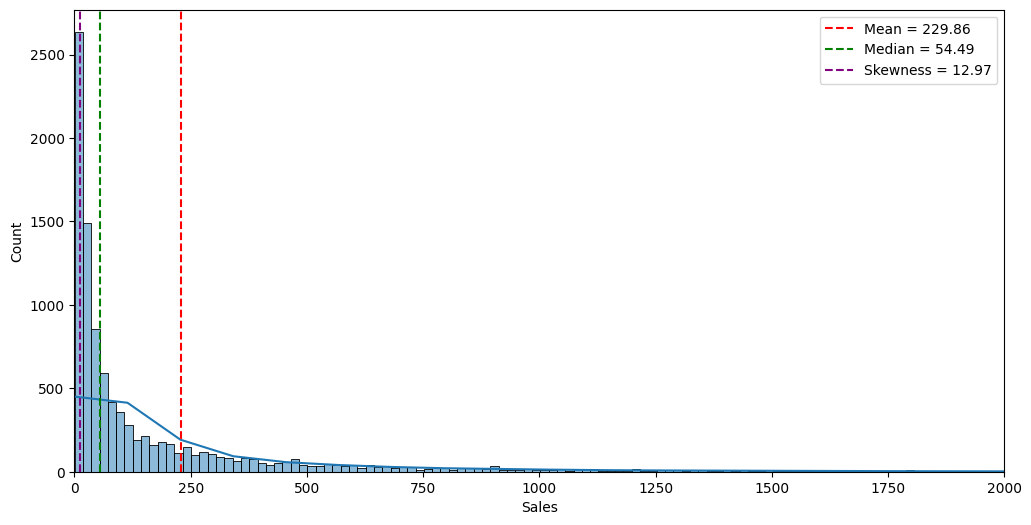

In [35]:
#Task 1
plt.figure(figsize=(12,6))
plt.xlim(0,2000)
mean=df['Sales'].mean()
median = df['Sales'].median()
skew = df['Sales'].skew()
#plt.xticks(range(0,20,500))
sns.histplot(data=df,x='Sales',kde=True)
plt.axvline(mean,color='red', linestyle='--', label=f'Mean = {mean:.2f}')
plt.axvline(median,color='green', linestyle='--', label=f'Median = {median:.2f}')
plt.axvline(skew,color='purple',linestyle='--',label = f'Skewness = {skew:.2f}')
plt.legend()
plt.show()


/tmp/ipykernel_2001/3984641618.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df,x='Category',y='Profit',palette='muted')


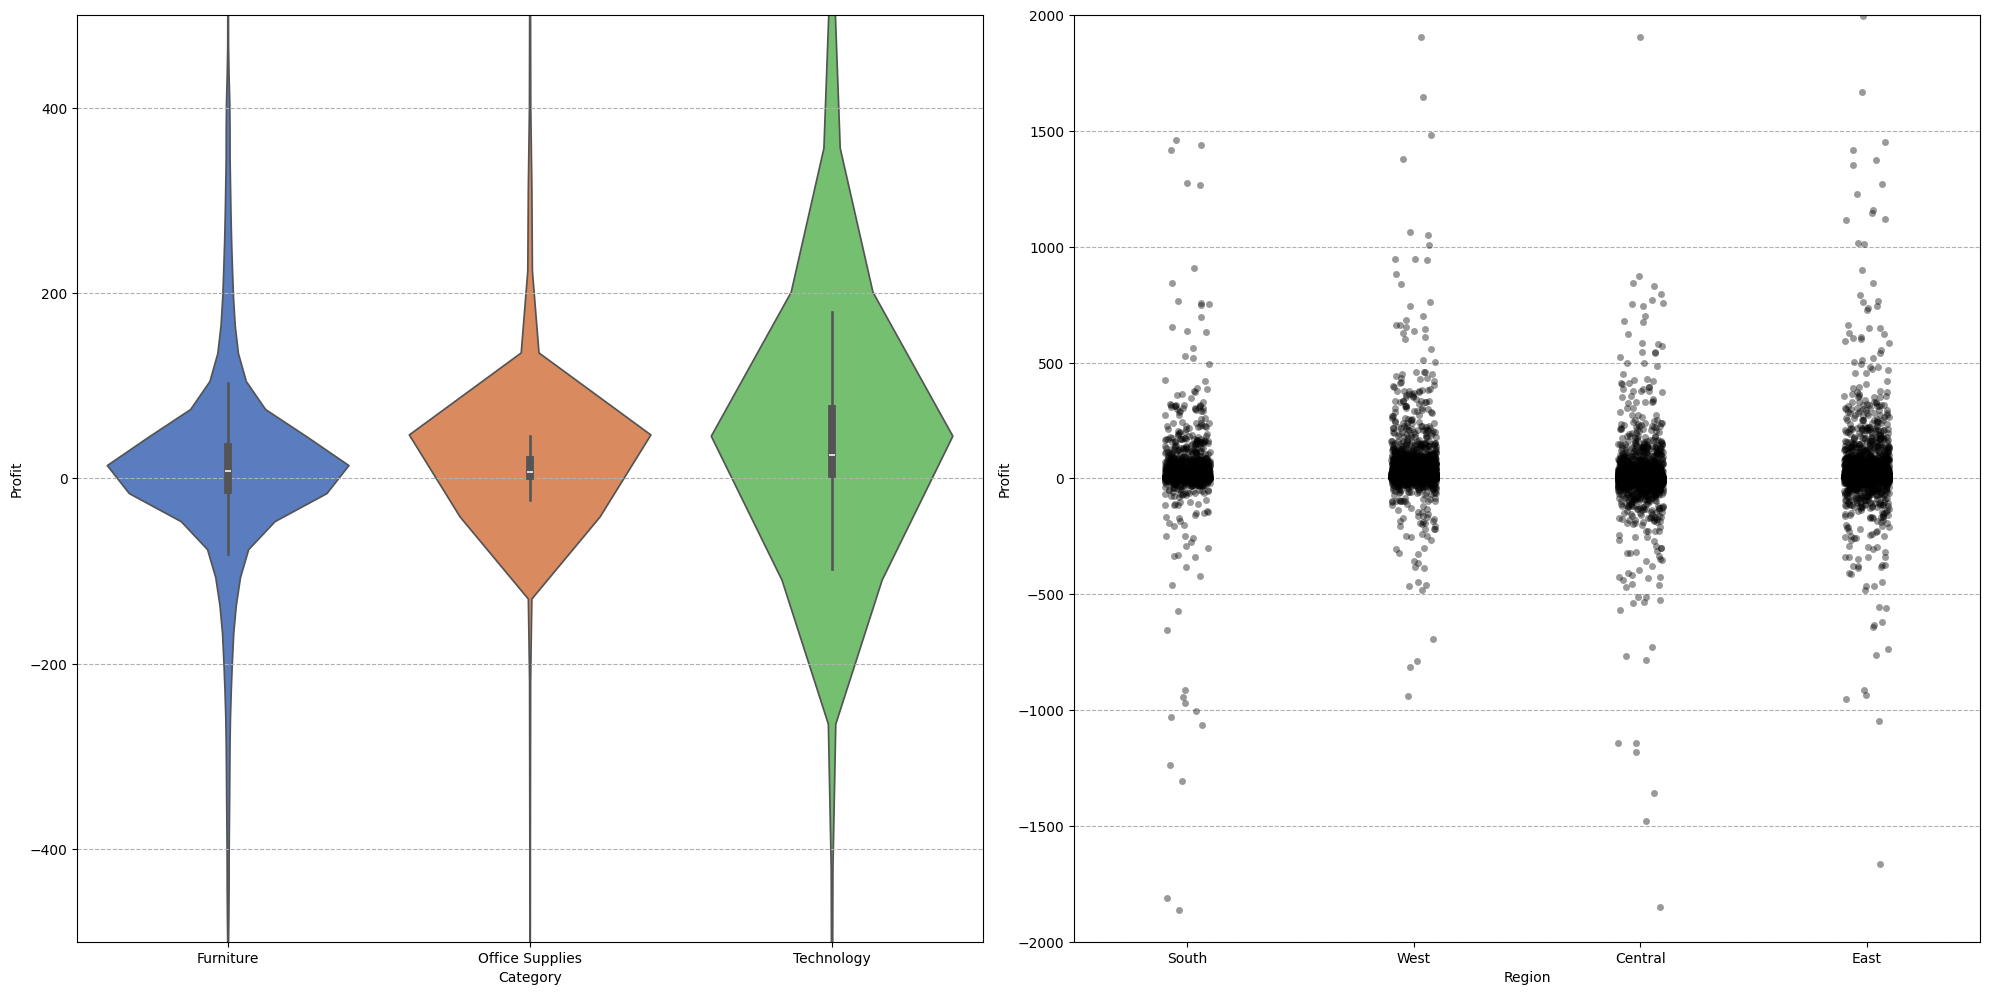

In [67]:
#Task 2
plt.figure(figsize=(20,10))
plt.subplot(1,2,1)
sns.violinplot(data=df,x='Category',y='Profit',palette='muted')
plt.ylim(-500,500)
plt.grid(axis='y',linestyle='--')



#Strip plot
plt.subplot(1,2,2)
sns.stripplot(data=df, x="Region", y="Profit", jitter=True,color='black',alpha=0.4)
plt.grid(axis='y',linestyle='--')
plt.tight_layout()
plt.ylim(-2000,2000)
plt.show()

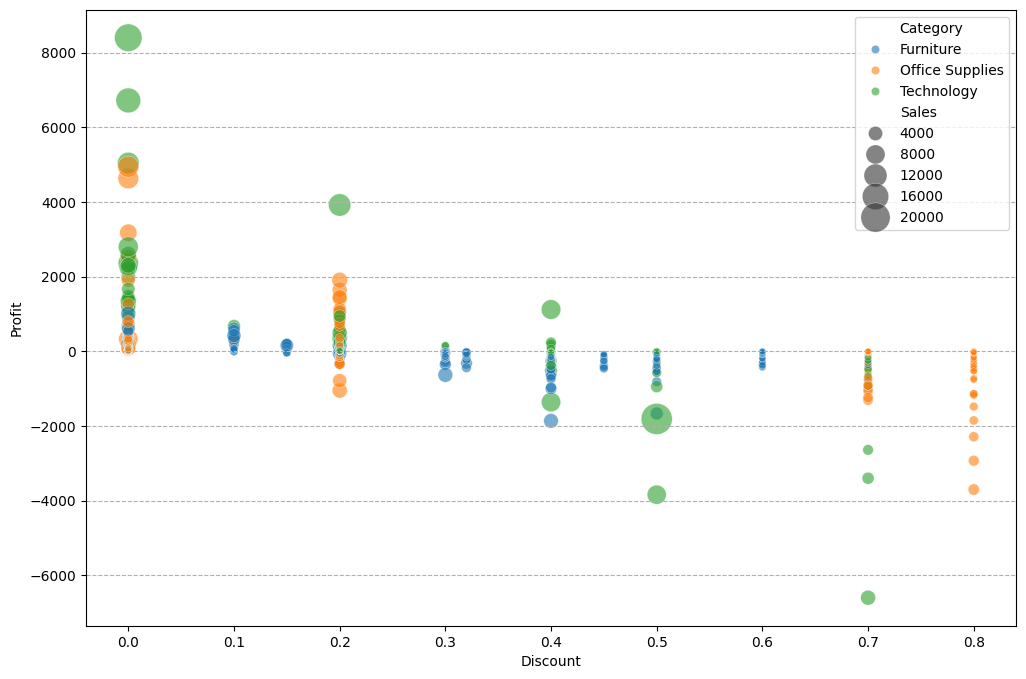

In [78]:
#Task 3
plt.figure(figsize=(12,8))
sns.scatterplot(data=df,x='Discount',y='Profit',hue ='Category',size='Sales',sizes=(20,500),alpha = 0.6)
plt.grid(axis='y',linestyle='--')
plt.show()

Pearson Correlation:
             Sales  Quantity  Discount    Profit
Sales     1.000000  0.200795 -0.028190  0.479064
Quantity  0.200795  1.000000  0.008623  0.066253
Discount -0.028190  0.008623  1.000000 -0.219487
Profit    0.479064  0.066253 -0.219487  1.000000

Spearman Correlation:
             Sales  Quantity  Discount    Profit
Sales     1.000000  0.327426 -0.056969  0.518407
Quantity  0.327426  1.000000 -0.000878  0.234491
Discount -0.056969 -0.000878  1.000000 -0.543350
Profit    0.518407  0.234491 -0.543350  1.000000

Most noticeable disagreement: ('Discount', 'Profit')
Pearson: -0.21948745637176792
Spearman: -0.5433501822306211


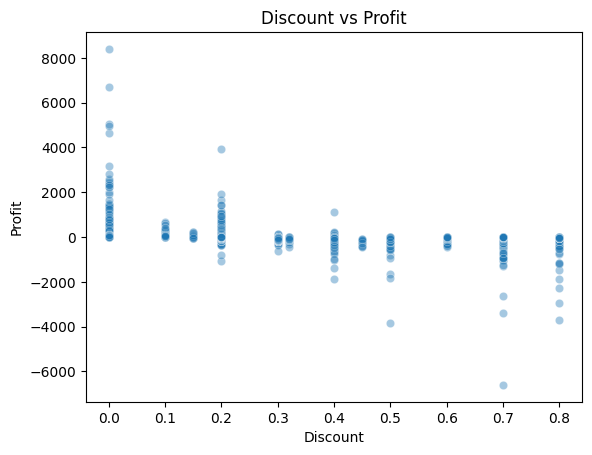

In [81]:
#Task4
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

numeric_cols = ['Sales', 'Quantity', 'Discount', 'Profit']

# Pearson correlation
pearson = df[numeric_cols].corr(method='pearson')

# Spearman correlation
spearman = df[numeric_cols].corr(method='spearman')

print("Pearson Correlation:")
print(pearson)

print("\nSpearman Correlation:")
print(spearman)

difference = abs(pearson - spearman)

# Remove diagonal
for col in difference.columns:
    difference.loc[col, col] = 0

pair = difference.stack().idxmax()

print("\nMost noticeable disagreement:", pair)
print("Pearson:", pearson.loc[pair[0], pair[1]])
print("Spearman:", spearman.loc[pair[0], pair[1]])


x = pair[0]
y = pair[1]

sns.scatterplot(data=df, x=x, y=y, alpha=0.4)

plt.title(f"{x} vs {y}")
plt.show()

Category    Furniture  Office Supplies  Technology           All
Region                                                          
Central   163797.1638       167026.415  170416.312  5.012399e+05
East      208291.2040       205516.055  264973.981  6.787812e+05
South     117298.6840       125651.313  148771.908  3.917219e+05
West      252612.7435       220853.249  251991.832  7.254578e+05
All       741999.7953       719047.032  836154.033  2.297201e+06


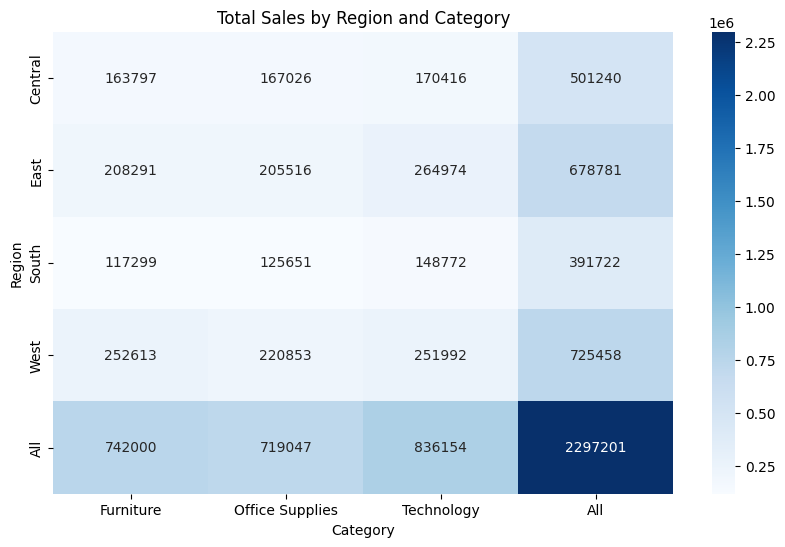

Highest revenue combination: ('East', 'Technology')
Total Sales: 264973.981


In [83]:
#Task 5
pivot = pd.pivot_table(
    df,
    values='Sales',
    index='Region',
    columns='Category',
    aggfunc='sum',
    margins=True
)

print(pivot)

plt.figure(figsize=(10,6))

sns.heatmap(
    pivot,
    annot=True,
    fmt='.0f',
    cmap='Blues'
)

plt.title('Total Sales by Region and Category')
plt.xlabel('Category')
plt.ylabel('Region')

plt.show()

combination = pivot.drop(index='All').drop(columns='All').stack().idxmax()
value = pivot.loc[combination[0], combination[1]]

print("Highest revenue combination:", combination)
print("Total Sales:", value)

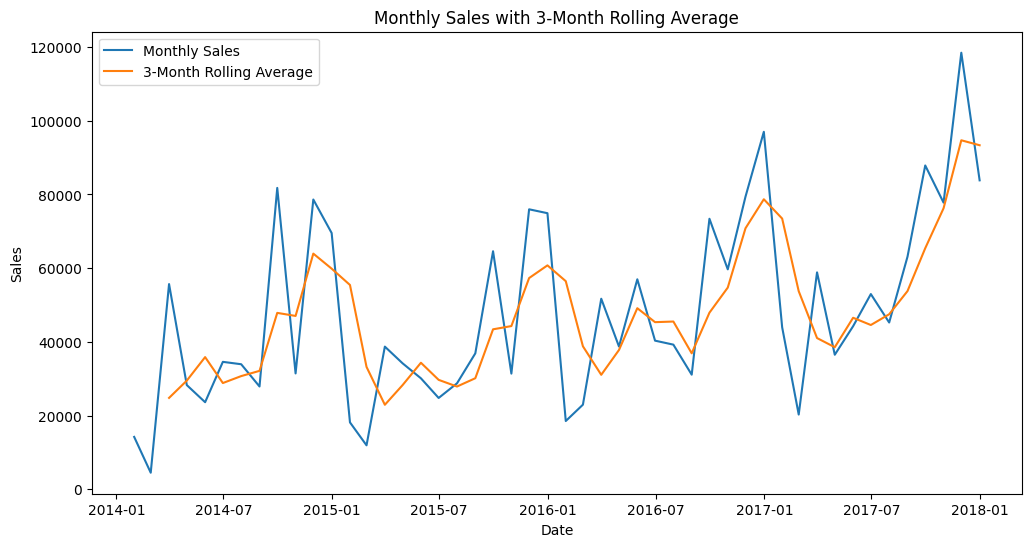

In [84]:
#Task6
df['Order Date'] = pd.to_datetime(df['Order Date'])
monthly_sales = (
    df.set_index('Order Date')['Sales']
    .resample('ME')
    .sum()
)

rolling_sales = monthly_sales.rolling(3).mean()
plt.figure(figsize=(12,6))

plt.plot(monthly_sales, label='Monthly Sales')
plt.plot(rolling_sales, label='3-Month Rolling Average')

plt.xlabel('Date')
plt.ylabel('Sales')
plt.title('Monthly Sales with 3-Month Rolling Average')

plt.legend()
plt.show()

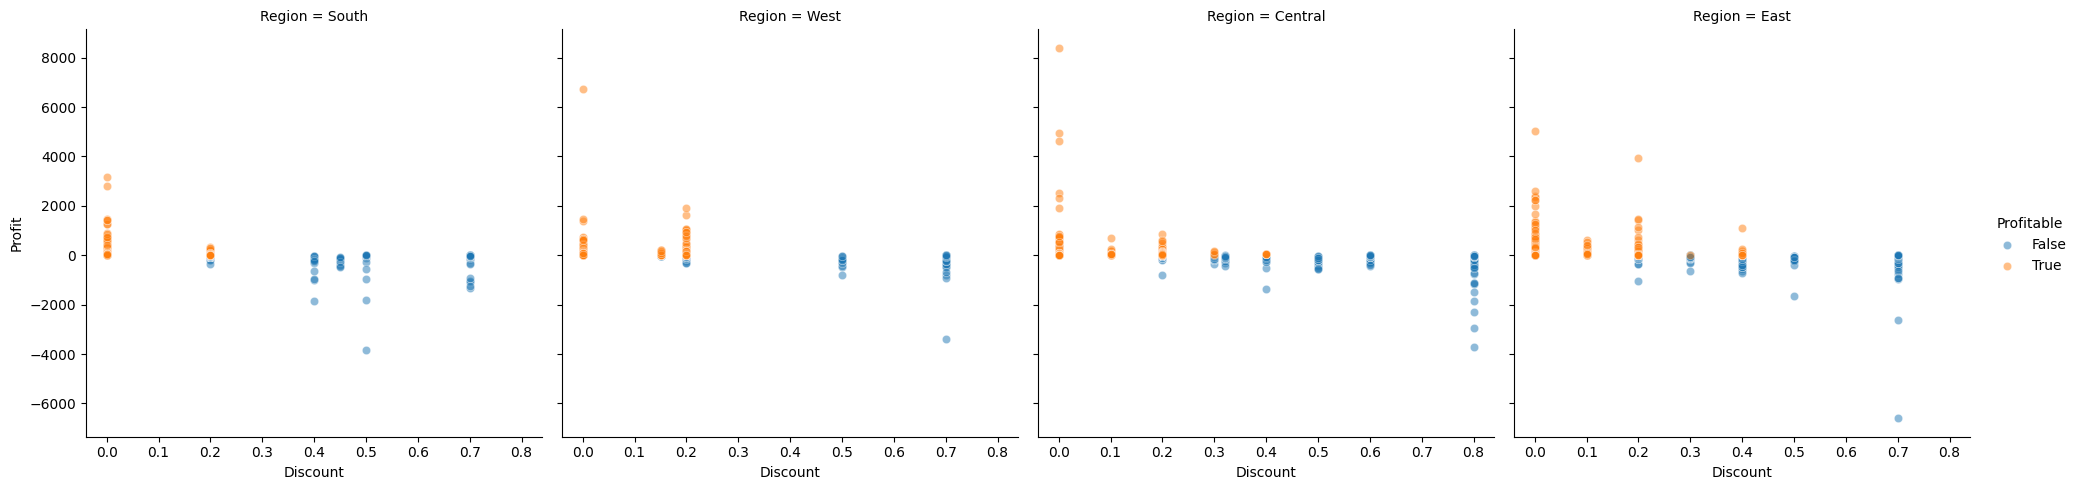

In [90]:
df['Profitable'] = df['Profit'] > 0

g = sns.FacetGrid(
    df,
    col='Region',
    hue='Profitable',
    height=5
)

g.map(sns.scatterplot, 'Discount', 'Profit', alpha=0.5)

g.add_legend()

plt.show()


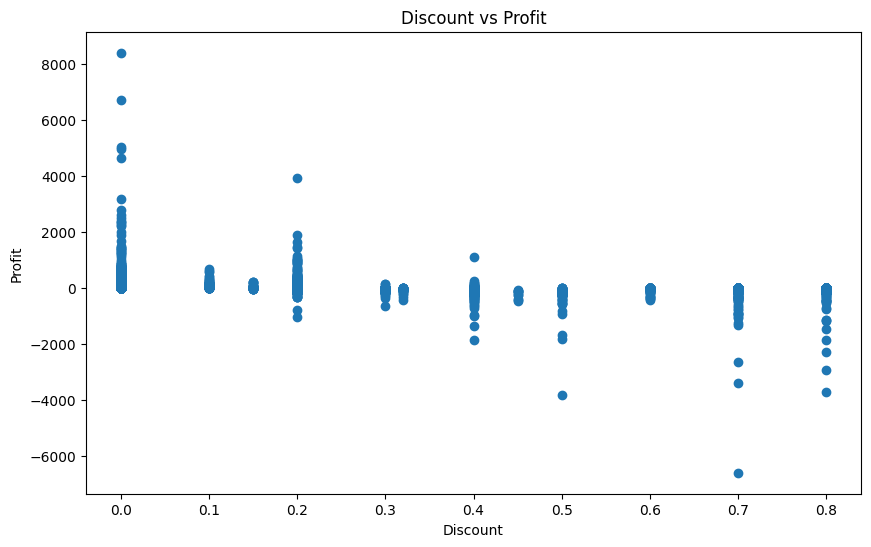

In [86]:
#Task8
plt.figure(figsize=(10,6))

plt.scatter(df['Discount'], df['Profit'])

plt.xlabel('Discount')
plt.ylabel('Profit')
plt.title('Discount vs Profit')

plt.show()



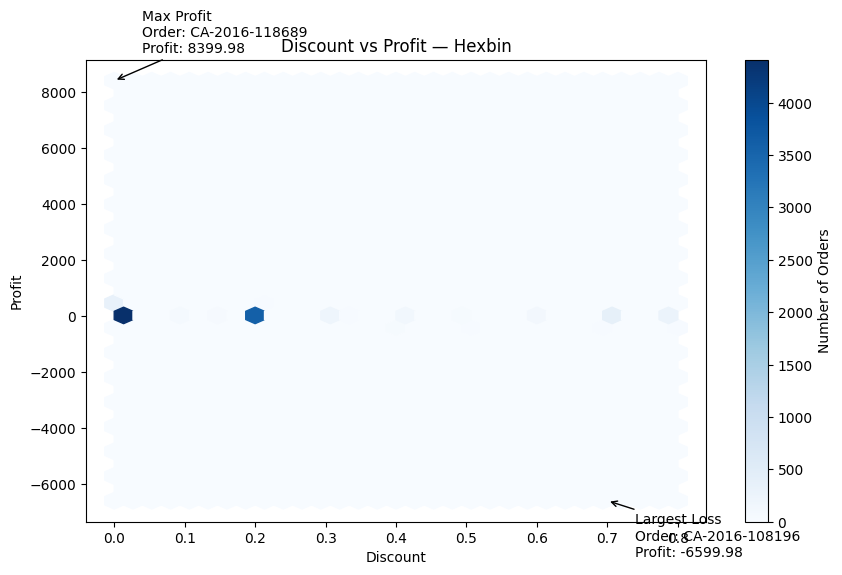

In [89]:
plt.figure(figsize=(10,6))

plt.hexbin(
    df['Discount'],
    df['Profit'],
    gridsize=30,
    cmap='Blues'
)

plt.colorbar(label='Number of Orders')

plt.xlabel('Discount')
plt.ylabel('Profit')
plt.title('Discount vs Profit — Hexbin')
max_profit = df.loc[df['Profit'].idxmax()]
max_loss = df.loc[df['Profit'].idxmin()]
plt.annotate(
    f"Max Profit\nOrder: {max_profit['Order ID']}\nProfit: {max_profit['Profit']:.2f}",
    xy=(max_profit['Discount'], max_profit['Profit']),
    xytext=(20, 20),
    textcoords='offset points',
    arrowprops=dict(arrowstyle='->')
)

plt.annotate(
    f"Largest Loss\nOrder: {max_loss['Order ID']}\nProfit: {max_loss['Profit']:.2f}",
    xy=(max_loss['Discount'], max_loss['Profit']),
    xytext=(20, -40),
    textcoords='offset points',
    arrowprops=dict(arrowstyle='->')
)

plt.show()